In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

In [ ]:
X = np.load('..\Function_5_Data\Week_2_Data/F5_Week_2_inputs.npy')
Y = np.load('..\Function_5_Data\Week_2_Data/F5_Week_2_outputs.npy')
X.shape, Y

((21, 4),
 array([6.44434399e+01, 1.83013796e+01, 1.12939795e-01, 4.21089813e+00,
        2.58370525e+02, 7.84343889e+01, 5.75715369e+01, 1.09571876e+02,
        8.84799176e+00, 2.33223610e+02, 2.44230883e+01, 6.44201468e+01,
        6.34767158e+01, 7.97291299e+01, 3.55806818e+02, 1.08885962e+03,
        2.88667516e+01, 4.51815703e+01, 4.31612757e+02, 9.97233189e+00,
        1.94327367e+03]))

In [43]:
Y_max=Y[0:-1].max()
Y_max_new=Y.max()
Y_max, Y_max_new

(np.float64(1088.8596181962705), np.float64(1943.2736664714075))

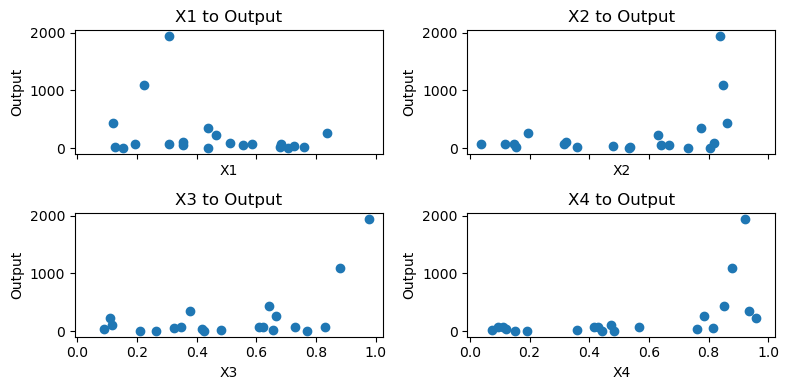

In [35]:
# Create 2 subplots
fig, axes = plt.subplots(2, 2, figsize=(8, 4), sharex=True)

# Scatterplots
axes[0,0].scatter(X[:,0], Y)
axes[0,0].set_title('X1 to Output')
axes[0,0].set_xlabel('X1')
axes[0,0].set_ylabel('Output')

axes[0,1].scatter(X[:,1], Y)
axes[0,1].set_title('X2 to Output')
axes[0,1].set_xlabel('X2')
axes[0,1].set_ylabel('Output')

axes[1,0].scatter(X[:,2], Y)
axes[1,0].set_title('X3 to Output')
axes[1,0].set_xlabel('X3')
axes[1,0].set_ylabel('Output')

axes[1,1].scatter(X[:,3], Y)
axes[1,1].set_title('X4 to Output')
axes[1,1].set_xlabel('X4')
axes[1,1].set_ylabel('Output')

plt.tight_layout()
plt.show()

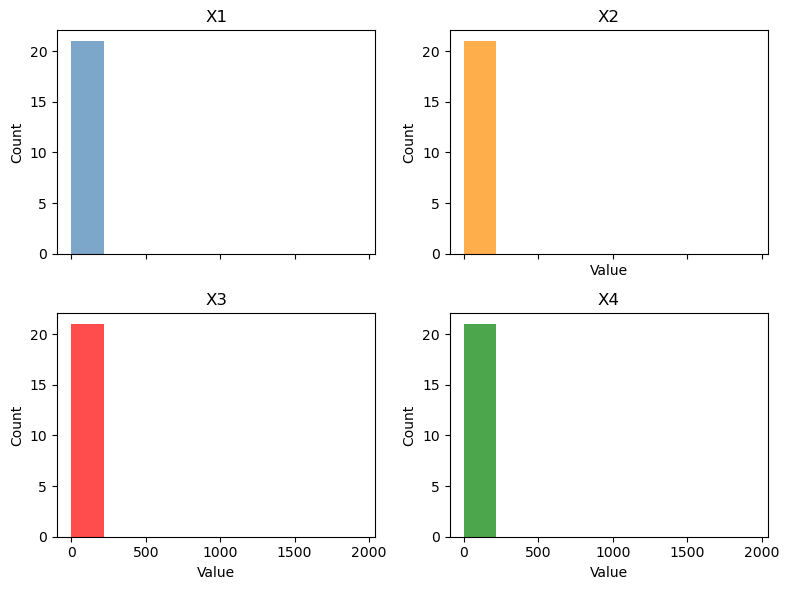

In [45]:
# Create 3 subplots
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True)

# Use common bins for easy comparison
bins = np.linspace(
    min(X[:,0].min(), X[:,1].min(), X[:,2].min(), X[:,3].min(), Y.min()),
    max(X[:,0].max(), X[:,1].max(), X[:,2].max(), X[:,3].max(), Y.max()),
    10
)

# Histogram of first array
axes[0,0].hist(X[:,0], bins=bins, color='steelblue', alpha=0.7)
axes[0,0].set_title('X1')
axes[0,0].set_ylabel('Count')

# Histogram of second array
axes[0,1].hist(X[:,1], bins=bins, color='darkorange', alpha=0.7)
axes[0,1].set_title('X2')
axes[0,1].set_xlabel('Value')
axes[0,1].set_ylabel('Count')

# Histogram of third array
axes[1,0].hist(X[:,2], bins=bins, color='red', alpha=0.7)
axes[1,0].set_title('X3')
axes[1,0].set_xlabel('Value')
axes[1,0].set_ylabel('Count')

# Histogram of target
axes[1,1].hist(X[:,2], bins=bins, color='green', alpha=0.7)
axes[1,1].set_title('X4')
axes[1,1].set_xlabel('Value')
axes[1,1].set_ylabel('Count')

plt.tight_layout()
plt.show()

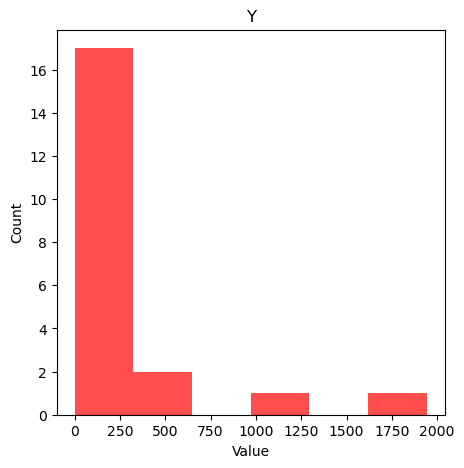

In [37]:
fig, axes = plt.subplots(1, 1, figsize=(5, 5), sharex=True)
# Histogram of third array
plt.hist(Y, bins=bins, color='red', alpha=0.7)
plt.title('Y')
plt.xlabel('Value')
plt.ylabel('Count')
plt.show()

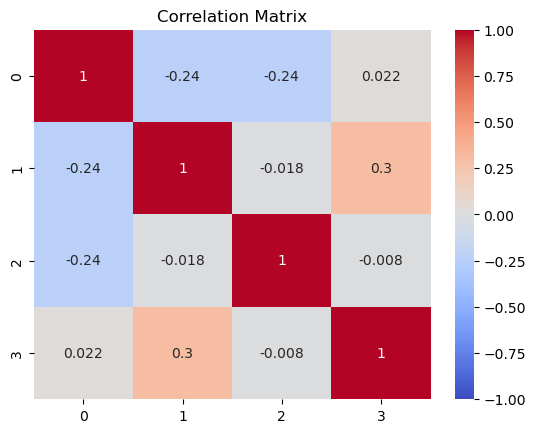

In [38]:
df=pd.DataFrame(data=X)
corr = df.corr()

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            vmin=-1,
            vmax=1)

plt.title("Correlation Matrix")
plt.show()

In [39]:
length_scale_vector = np.ones(X.shape[1])
#kernel = Matern(length_scale=length_scale_vector, nu=2.5)
kernel = ConstantKernel(1.0) * RBF(length_scale=length_scale_vector)
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6, n_restarts_optimizer=10)
gp.fit(X, Y)

,kernel,"1**2 * RBF(le...=[1, 1, 1, 1])"
,alpha,1e-06
,optimizer,'fmin_l_bfgs_b'
,n_restarts_optimizer,10
,normalize_y,False
,copy_X_train,True
,n_targets,None
,random_state,None
,kernel__k1,1**2
,kernel__k2,"RBF(length_scale=[1, 1, 1, 1])"
,kernel__k1__constant_value,1.0


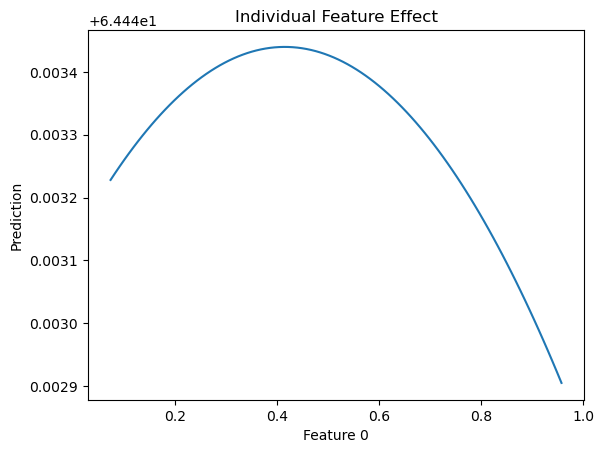

In [55]:
sample = X[0].copy()

feature = 3

values = np.linspace(
    X[:, feature].min(),
    X[:, feature].max(),
    100
)

predictions = []

for v in values:
    temp = sample.copy()
    temp[feature] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions.append(pred)

plt.plot(values, predictions)
plt.xlabel("Feature 0")
plt.ylabel("Prediction")
plt.title("Individual Feature Effect")
plt.show()

In [40]:
def upper_confidence_bound(mu, sigma, kappa=2.0):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma

def lower_confidence_bound(mu, sigma, kappa=2.0):
    """
    Lower Confidence Bound (UCB) acquisition function.
    LCB = mean - kappa * std
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu - kappa * sigma

def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei


In [41]:
def acq_objective(X):
    X = X.reshape(1, -1)
    mu, sigma = gp.predict(X, return_std=True)
               
    if acquisition == 'ei':
        acq_val = expected_improvement(mu, sigma, Y.max())
    elif acquisition == 'lcb':
        acq_val = lower_confidence_bound(mu, sigma, kappa=2.5)
    else:
        acq_val = upper_confidence_bound(mu, sigma, kappa=2.5)
           
    return -acq_val  # Negative because we use the 'minimize' function later

In [42]:
acquisition='lcb'
n_dims=X.shape[1]
bounds = [(0, 1) for _ in range(n_dims)]
best_acq = np.inf
X_next = None

bounds = [(0, 1) for _ in range(n_dims)]
for _ in range(30):  # Multiple random starts
    x0 = np.random.uniform(0, 1, n_dims)
    result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
    if result.fun < best_acq:
        best_acq = result.fun
        X_next = result.x

print(f'New query: {X_next[0]:.6f}-{X_next[1]:.6f}-{X_next[2]:.6f}-{X_next[3]:.6f}')

New query: 0.669674-0.846480-0.879484-0.839774
